In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

ROOT = Path('/content/drive/MyDrive/Logika Ui')
if not ROOT.exists():
    from google.colab import drive
    drive.mount('/content/drive')
HASIL = ROOT / 'KTI_KARHUTLA' / 'hasil'
BERKAS = HASIL / 'tabel_gabungan_nasional_semua_bulan.csv'

semua = pd.read_csv(BERKAS, nrows=0).columns
him = [c for c in semua if c.startswith('him_') and c not in ('him_n', 'him_f5')]
d = pd.read_csv(BERKAS, usecols=['bulan', 'hujan_rata', 'frac_hujan', 'him_n'] + him)
d = d[d['him_n'].notna()].reset_index(drop=True)
print(len(d), 'baris dengan Himawari |', len(him), 'variabel:', him)


def kelas_dari(tau):
    return np.where(d['hujan_rata'] * 6 >= 1, 2, np.where(d['frac_hujan'] >= tau, 1, 0)).astype(int)


d['kelas'] = kelas_dari(0.05)

Mounted at /content/drive
1068170 baris dengan Himawari | 11 variabel: ['him_suhu_mean', 'him_suhu_p10', 'him_suhu_min', 'him_lt273', 'him_lt253', 'him_lt233', 'him_f0', 'him_f1', 'him_f2', 'him_f3', 'him_f4']


In [2]:
def auc2(x, y, a, b):
    m = d['kelas'].isin([a, b]) & x.notna()
    return roc_auc_score(d.loc[m, 'kelas'] == b, x[m])


baris = []
for c in him:
    x = d[c]
    med = [x[d['kelas'] == k].median() for k in (0, 1, 2)]
    baris.append({'variabel': c, 'median_K0': med[0], 'median_K1': med[1], 'median_K2': med[2],
                  'AUC_K1_vs_K0': auc2(x, d['kelas'], 0, 1), 'AUC_K2_vs_K1': auc2(x, d['kelas'], 1, 2)})
tabel_a = pd.DataFrame(baris)
tabel_a['antara'] = ((tabel_a['median_K1'] - tabel_a['median_K0']) * (tabel_a['median_K2'] - tabel_a['median_K1']) > 0)
tabel_a['kekuatan'] = (tabel_a['AUC_K1_vs_K0'] - 0.5).abs()
tabel_a = tabel_a.sort_values('kekuatan', ascending=False).drop(columns='kekuatan')
print(tabel_a.round(3).to_string(index=False))
print('\nvariabel dengan urutan K0, K1, K2 yang searah:', int(tabel_a['antara'].sum()), 'dari', len(tabel_a))
tabel_a.round(4).to_csv(HASIL / 'validasi_fisis_K1_tabel.csv', index=False)

     variabel  median_K0  median_K1  median_K2  AUC_K1_vs_K0  AUC_K2_vs_K1  antara
       him_f0      0.348      0.100      0.048         0.234         0.381    True
       him_f4      0.351      0.777      0.875         0.760         0.605    True
    him_lt273      0.624      0.917      0.951         0.746         0.582    True
    him_lt253      0.506      0.833      0.892         0.731         0.581    True
him_suhu_mean    252.755    232.535    227.964         0.279         0.412    True
    him_lt233      0.383      0.678      0.756         0.697         0.570    True
       him_f1      0.197      0.076      0.048         0.303         0.425    True
 him_suhu_p10    220.386    212.483    210.159         0.326         0.404    True
       him_f3      0.001      0.004      0.005         0.633         0.495    True
 him_suhu_min    192.777    186.154    184.096         0.368         0.445    True
       him_f2      0.001      0.001      0.001         0.558         0.469   False

var

In [3]:
musim = d['bulan'].between(6, 10)
kunci = [c for c in ('him_lt233', 'him_suhu_p10') if c in him]
for c in kunci:
    s = d.loc[musim, [c, 'kelas']].dropna()
    med = [s.loc[s['kelas'] == k, c].median() for k in (0, 1, 2)]
    dua = s[s['kelas'].isin([0, 1])]
    print(c, '| median K0/K1/K2:', [round(v, 3) for v in med],
          '| AUC K1 vs K0:', round(roc_auc_score(dua['kelas'] == 1, dua[c]), 3))

him_lt233 | median K0/K1/K2: [0.253, 0.577, 0.691] | AUC K1 vs K0: 0.706
him_suhu_p10 | median K0/K1/K2: [227.18, 216.024, 213.08] | AUC K1 vs K0: 0.315


In [4]:
hasil = []
for tau in (0.02, 0.05, 0.10, 0.20):
    k = kelas_dari(tau)
    for c in kunci:
        med = [d.loc[k == i, c].median() for i in (0, 1, 2)]
        hasil.append({'ambang': tau, 'variabel': c, 'persen_K1': round(100 * (k == 1).mean(), 1),
                      'median_K0': med[0], 'median_K1': med[1], 'median_K2': med[2],
                      'urutan_searah': (med[1] - med[0]) * (med[2] - med[1]) > 0})
print(pd.DataFrame(hasil).round(3).to_string(index=False))

 ambang     variabel  persen_K1  median_K0  median_K1  median_K2  urutan_searah
   0.02    him_lt233       32.7      0.325      0.658      0.756           True
   0.02 him_suhu_p10       32.7    222.622    212.894    210.159           True
   0.05    him_lt233       25.8      0.383      0.678      0.756           True
   0.05 him_suhu_p10       25.8    220.386    212.483    210.159           True
   0.10    him_lt233       16.5      0.446      0.699      0.756           True
   0.10 him_suhu_p10       16.5    218.239    212.068    210.159           True
   0.20    him_lt233        5.8      0.502      0.712      0.756           True
   0.20 him_suhu_p10        5.8    216.412    211.748    210.159           True


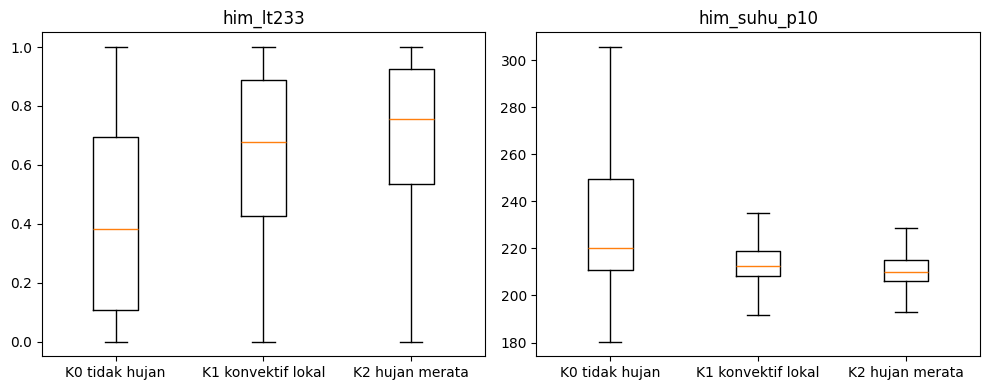

In [5]:
fig, ax = plt.subplots(1, len(kunci), figsize=(5 * len(kunci), 4))
ax = np.atleast_1d(ax)
for a, c in zip(ax, kunci):
    a.boxplot([d.loc[d['kelas'] == k, c].dropna() for k in (0, 1, 2)], showfliers=False,
              tick_labels=['K0 tidak hujan', 'K1 konvektif lokal', 'K2 hujan merata'])
    a.set_title(c)
plt.tight_layout()
plt.savefig(HASIL / 'validasi_fisis_K1.png', dpi=200)
plt.show()